# Anomaly Detection: Evaluating Models Beyond Accuracy

Fraud detection is a classic anomaly detection problem: the cases you care about most are rare. In this notebook we use a real dataset of credit card transactions, where fewer than 2 in 1,000 transactions are fraudulent, to walk through a practical workflow:

* Framing the problem (what decision are we supporting?)
* Feature engineering
* Leakage
* Why accuracy is misleading for rare events
* Comparing model families (supervised and unsupervised)
* Confusion matrices, precision, recall, F1, ROC-AUC, and PR-AUC

**The data:** 284,807 transactions made by European cardholders over two days in September 2013, 492 of them fraudulent. It was released by Worldline and the Machine Learning Group at Université Libre de Bruxelles ([Dal Pozzolo et al., 2015](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)). To protect cardholders, most columns (`V1` to `V28`) are anonymized: they are principal components of the original features. Only `Time` and `Amount` are in their original form.

## Import Libraries

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.utils import resample

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.neighbors import LocalOutlierFactor

from sklearn import metrics

## Load the Dataset
Each row is one credit card transaction. The target `Class` is 1 if the transaction was fraudulent.

In [2]:
DATA_URL = 'https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'
DATA_PATH = Path('data/creditcard.csv')

# Download the data once (about 150 MB), then read the local copy
if not DATA_PATH.exists():
    urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH)

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.shape

(284807, 31)

Fraud is extremely rare, which is what makes this an anomaly detection problem.

In [5]:
df['Class'].value_counts(normalize=True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

## Framing the Problem

Before choosing a model, be clear about the decision the model supports.

* **Decision:** Which transactions should be flagged for a fraud analyst to review?
* **Target:** `Class` (1 = fraud, 0 = legitimate).
* **Features:** Only information available *at the moment of the transaction*.
* **Label quality:** Fraud labels often arrive weeks later, and some fraud is never reported. In practice you may have very few reliable labels.
* **Costs of errors:** A false negative (missed fraud) costs money. A false positive (flagging a legitimate purchase) costs analyst time and annoys customers.

## Feature Engineering

`Time` is the number of seconds since the first transaction in the dataset, which is not useful on its own. Converting it to the **hour of the day** gives the model something meaningful. (The dataset counts from its first transaction, not from midnight, so treat these hours as approximate clock times.) Fraud is far more common in the early hours, when there are few legitimate purchases.

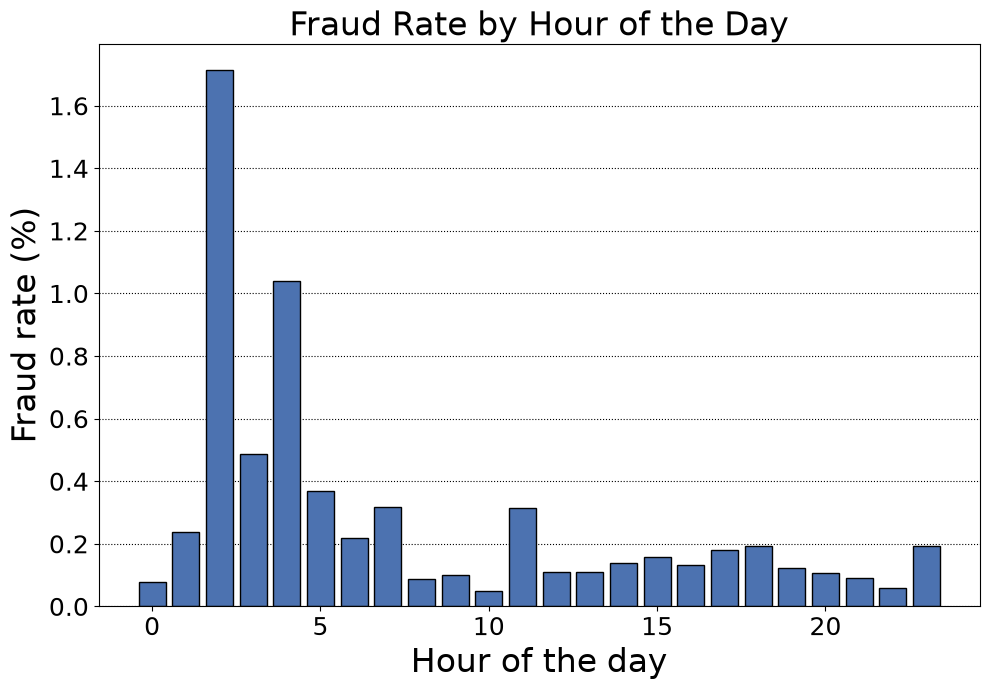

In [6]:
df['hour'] = (df['Time'] // 3600) % 24
df['log_amount'] = np.log1p(df['Amount'])

fraud_rate_by_hour = df.groupby('hour')['Class'].mean() * 100

fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (10,7), facecolor = 'white')
ax.bar(fraud_rate_by_hour.index, fraud_rate_by_hour.values, color='#4c72b0', edgecolor='black', zorder = 2)
ax.grid(True,
        axis = 'y',
        zorder = 0,
        linestyle = ':',
        color = 'k')
ax.tick_params(labelsize = 18)
ax.set_xlabel('Hour of the day', fontsize = 24)
ax.set_ylabel('Fraud rate (%)', fontsize = 24)
ax.set_title('Fraud Rate by Hour of the Day', fontsize = 24)
fig.tight_layout()

## Splitting Data into Training and Test Sets

Split before doing anything that uses the labels, including comparing features. With rare events, use `stratify` so the training and test sets have the same fraud rate. Our test set will have only about 120 frauds, so every one counts.

In [7]:
train_df, test_df = train_test_split(df, test_size=0.25, stratify=df['Class'], random_state=0)

We also take the log of `Amount`, because amounts are heavily skewed (most purchases are small, a few are very large). Does the model benefit from these features? Let's compare logistic regression with and without them using 5-fold cross-validation on the training set.

In [8]:
raw_features = [f'V{i}' for i in range(1, 29)] + ['Amount']
features = [f'V{i}' for i in range(1, 29)] + ['log_amount', 'hour']

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

for name, cols in [('Raw features', raw_features), ('Engineered features', features)]:
    scores = cross_validate(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                            train_df[cols], train_df['Class'], cv=cv, scoring='average_precision')
    print(f"{name:20s} PR-AUC: {scores['test_score'].mean():.3f}")

Raw features         PR-AUC: 0.768


Engineered features  PR-AUC: 0.771


The improvement is tiny. That is a real lesson: `V1` to `V28` were already engineered by the bank (they are principal components of many original features), so most of the signal is already there. Feature engineering pays off most when the features are raw. We keep the engineered features from here on.

In [9]:
X_train, y_train = train_df[features], train_df['Class']
X_test, y_test = test_df[features], test_df['Class']

## Leakage

**Target leakage** happens when a feature contains information that would not be available when the prediction is made. A classic example in fraud is a "chargeback filed" flag: it is extremely predictive, but a chargeback is filed *after* the fraud is discovered. This dataset only includes information known at transaction time, so it avoids that trap.

A closely related mistake is very common with this exact dataset: **oversampling before splitting**. Because fraud is rare, people often duplicate the fraud cases to balance the classes. If you do that *before* splitting, copies of the same fraudulent transaction end up in both the training and test sets, and the model is graded on transactions it has already memorized.

In [10]:
# Wrong: oversample the fraud cases, then split
fraud = df[df['Class'] == 1]
oversampled = pd.concat([df[df['Class'] == 0], resample(fraud, n_samples=20 * len(fraud), random_state=0)])

X_tr_leaky, X_te_leaky, y_tr_leaky, y_te_leaky = train_test_split(oversampled[features], oversampled['Class'],
                                                                  test_size=0.25, stratify=oversampled['Class'],
                                                                  random_state=0)

leaky_model = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)
leaky_model.fit(X_tr_leaky, y_tr_leaky)
leaky_scores = leaky_model.predict_proba(X_te_leaky)[:, 1]

print('Oversampled BEFORE splitting')
print(f'  PR-AUC: {metrics.average_precision_score(y_te_leaky, leaky_scores):.3f}')
print(f'  Recall: {metrics.recall_score(y_te_leaky, leaky_scores >= 0.5):.3f}')

Oversampled BEFORE splitting
  PR-AUC: 1.000
  Recall: 1.000


In [11]:
# Right: split first, then oversample only the training set
train_fraud = train_df[train_df['Class'] == 1]
train_oversampled = pd.concat([train_df[train_df['Class'] == 0],
                               resample(train_fraud, n_samples=20 * len(train_fraud), random_state=0)])

honest_model = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0)
honest_model.fit(train_oversampled[features], train_oversampled['Class'])
honest_scores = honest_model.predict_proba(X_test)[:, 1]

print('Oversampled the training set only')
print(f'  PR-AUC: {metrics.average_precision_score(y_test, honest_scores):.3f}')
print(f'  Recall: {metrics.recall_score(y_test, honest_scores >= 0.5):.3f}')

Oversampled the training set only
  PR-AUC: 0.851
  Recall: 0.740


Results that look too good to be true usually are. Always split first, and do anything that uses the labels (oversampling, feature selection, tuning) on the training data only.

## Why Accuracy is Misleading

A "model" that predicts every transaction is legitimate never catches any fraud, yet it has very high accuracy.

In [12]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
dummy_preds = dummy.predict(X_test)

print(f'Accuracy: {metrics.accuracy_score(y_test, dummy_preds):.4f}')
print(f'Recall:   {metrics.recall_score(y_test, dummy_preds):.3f}')

Accuracy: 0.9983
Recall:   0.000


For rare events, look at metrics that focus on the positive (fraud) class:

* **Precision:** Of the transactions we flagged, what fraction were actually fraud?
* **Recall:** Of all the fraud, what fraction did we catch?
* **F1:** The harmonic mean of precision and recall.
* **ROC-AUC:** How well the model ranks fraud above non-fraud across all thresholds. It can look optimistic when positives are rare.
* **PR-AUC (average precision):** Summarizes the precision-recall curve in one number between 0 and 1. A random model scores about the fraud rate (0.0017 here), so it is a more honest metric for rare events. We explain how to read it after the model comparison below.

## Comparing Model Families

We compare several supervised models using 5-fold stratified cross-validation on the **training set only**. The test set is saved for the final evaluation. (This cell takes a couple of minutes.)

Gradient-boosted trees use `class_weight='balanced'`. With this few frauds, the default settings struggle to learn the rare class.

In [13]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=0),
    'Random Forest': RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=0),
    'Gradient-Boosted Trees': HistGradientBoostingClassifier(class_weight='balanced', random_state=0),
}

results = []
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=['accuracy', 'roc_auc', 'average_precision'])
    results.append({'model': name,
                    'accuracy': scores['test_accuracy'].mean(),
                    'ROC-AUC': scores['test_roc_auc'].mean(),
                    'PR-AUC': scores['test_average_precision'].mean()})

results_df = pd.DataFrame(results).sort_values('PR-AUC', ascending=False)
results_df.round(4)

,model,accuracy,ROC-AUC,PR-AUC
2,Random Forest,0.9995,0.9550,0.8416
0,Logistic Regression,0.9992,0.9755,0.7706
1,Decision Tree,0.9995,0.8968,0.7586
3,Gradient-Boosted Trees,0.9981,0.9644,0.7529


Every model has about 99.9% accuracy, so accuracy cannot tell them apart. PR-AUC shows real differences.

**How to read PR-AUC.** Picture a fraud analyst working down a list of transactions sorted by the model's score, most suspicious first. Each time they find a fraud, note what fraction of the transactions reviewed so far were fraud (the precision at that point). PR-AUC is the average of those fractions over all the fraud in the data.

* **1.0 is perfect:** every fraud is ranked above every legitimate transaction, so the analyst catches all the fraud without reviewing a single legitimate purchase.
* **About 0.0017 (the fraud rate) is random:** the model finds fraud no faster than picking transactions at random.
* **Higher is better:** the analyst reviews fewer legitimate transactions for the same amount of fraud caught. Random Forest (0.84) beats Logistic Regression (0.77) because more of what it puts near the top of the list is actually fraud.

PR-AUC ignores how well a model handles the 99.8% of transactions that are legitimate and easy to get right, which is why it separates models that accuracy cannot. It also doesn't depend on a threshold. Choosing one is a separate decision, covered in `Turning_Scores_into_Decisions.ipynb`.

## Unsupervised Anomaly Detection (Limited Labels)

What if you have few or no fraud labels? Unsupervised methods learn what "normal" looks like and score how unusual each transaction is, without ever seeing `Class`.

* **Isolation Forest:** Anomalies are easier to isolate with random splits.
* **Local Outlier Factor:** A nearest-neighbor method that flags points in low-density regions. Nearest-neighbor search is slow on large data, so we fit it on a random sample of 20,000 training transactions.

We fit these without labels and then use the held-out labels only to evaluate them.

In [14]:
iso = make_pipeline(StandardScaler(), IsolationForest(n_jobs=-1, random_state=0))
iso.fit(X_train)

lof = make_pipeline(StandardScaler(), LocalOutlierFactor(n_neighbors=50, novelty=True, n_jobs=-1))
lof.fit(X_train.sample(20000, random_state=0))

# score_samples returns higher values for normal points, so flip the sign to get an anomaly score
anomaly_scores = {'Isolation Forest': -iso.score_samples(X_test),
                  'Local Outlier Factor': -lof.score_samples(X_test)}

for name, scores in anomaly_scores.items():
    print(f'{name} ROC-AUC: {metrics.roc_auc_score(y_test, scores):.3f} '
          f'PR-AUC: {metrics.average_precision_score(y_test, scores):.3f}')

Isolation Forest ROC-AUC: 0.949 PR-AUC: 0.132
Local Outlier Factor ROC-AUC: 0.956 PR-AUC: 0.353


Unsupervised methods do far better than random (PR-AUC 0.0017) but worse than supervised models. When you have labels, use them. When you don't, unsupervised scores are a useful starting point for deciding which cases to label.

## Evaluating on the Test Set

In [15]:
fitted = {}
for name, model in models.items():
    fitted[name] = make_pipeline(StandardScaler(), model).fit(X_train, y_train)

test_scores = {name: pipe.predict_proba(X_test)[:, 1] for name, pipe in fitted.items()}
test_scores.update(anomaly_scores)

### Confusion Matrix
Using the random forest's default threshold of 0.5:

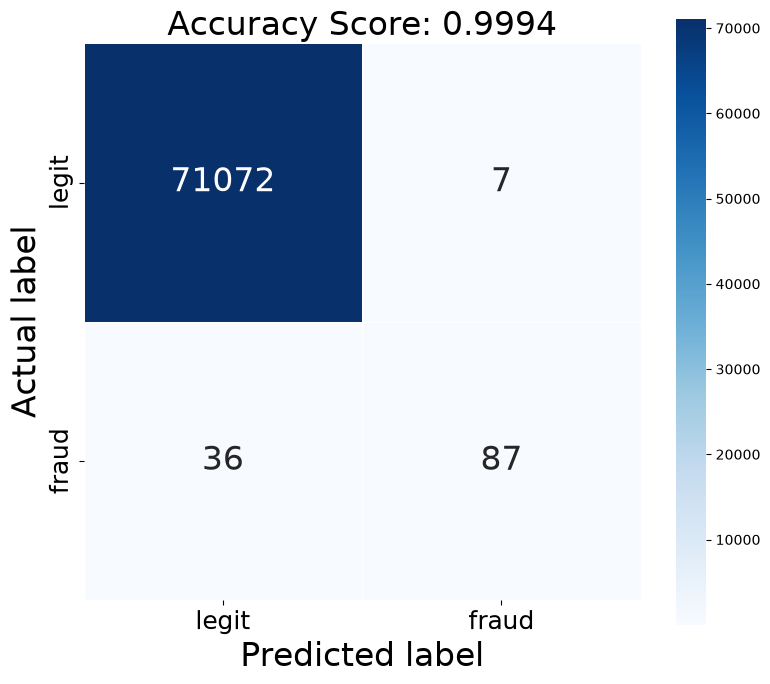

In [16]:
clf = fitted['Random Forest']
preds = clf.predict(X_test)

cm = metrics.confusion_matrix(y_test, preds)

fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (8,7), facecolor = 'white')
sns.heatmap(cm, annot=True, fmt='d',
            annot_kws={'size': 24},
            linewidths=.5,
            square = True,
            cmap = 'Blues',
            xticklabels=['legit', 'fraud'],
            yticklabels=['legit', 'fraud'],
            ax = ax)
ax.tick_params(labelsize = 18)
ax.set_ylabel('Actual label', fontsize = 24)
ax.set_xlabel('Predicted label', fontsize = 24)
ax.set_title(f'Accuracy Score: {metrics.accuracy_score(y_test, preds):.4f}', fontsize = 24)
fig.tight_layout()

In [17]:
print(metrics.classification_report(y_test, preds, target_names=['legit', 'fraud'], digits=3))

              precision    recall  f1-score   support

       legit      0.999     1.000     1.000     71079
       fraud      0.926     0.707     0.802       123

    accuracy                          0.999     71202
   macro avg      0.963     0.854     0.901     71202
weighted avg      0.999     0.999     0.999     71202



Accuracy is nearly perfect, but recall for fraud tells a different story. The default threshold of 0.5 is not necessarily the right one, which we explore in `Turning_Scores_into_Decisions.ipynb`.

### ROC and Precision-Recall Curves

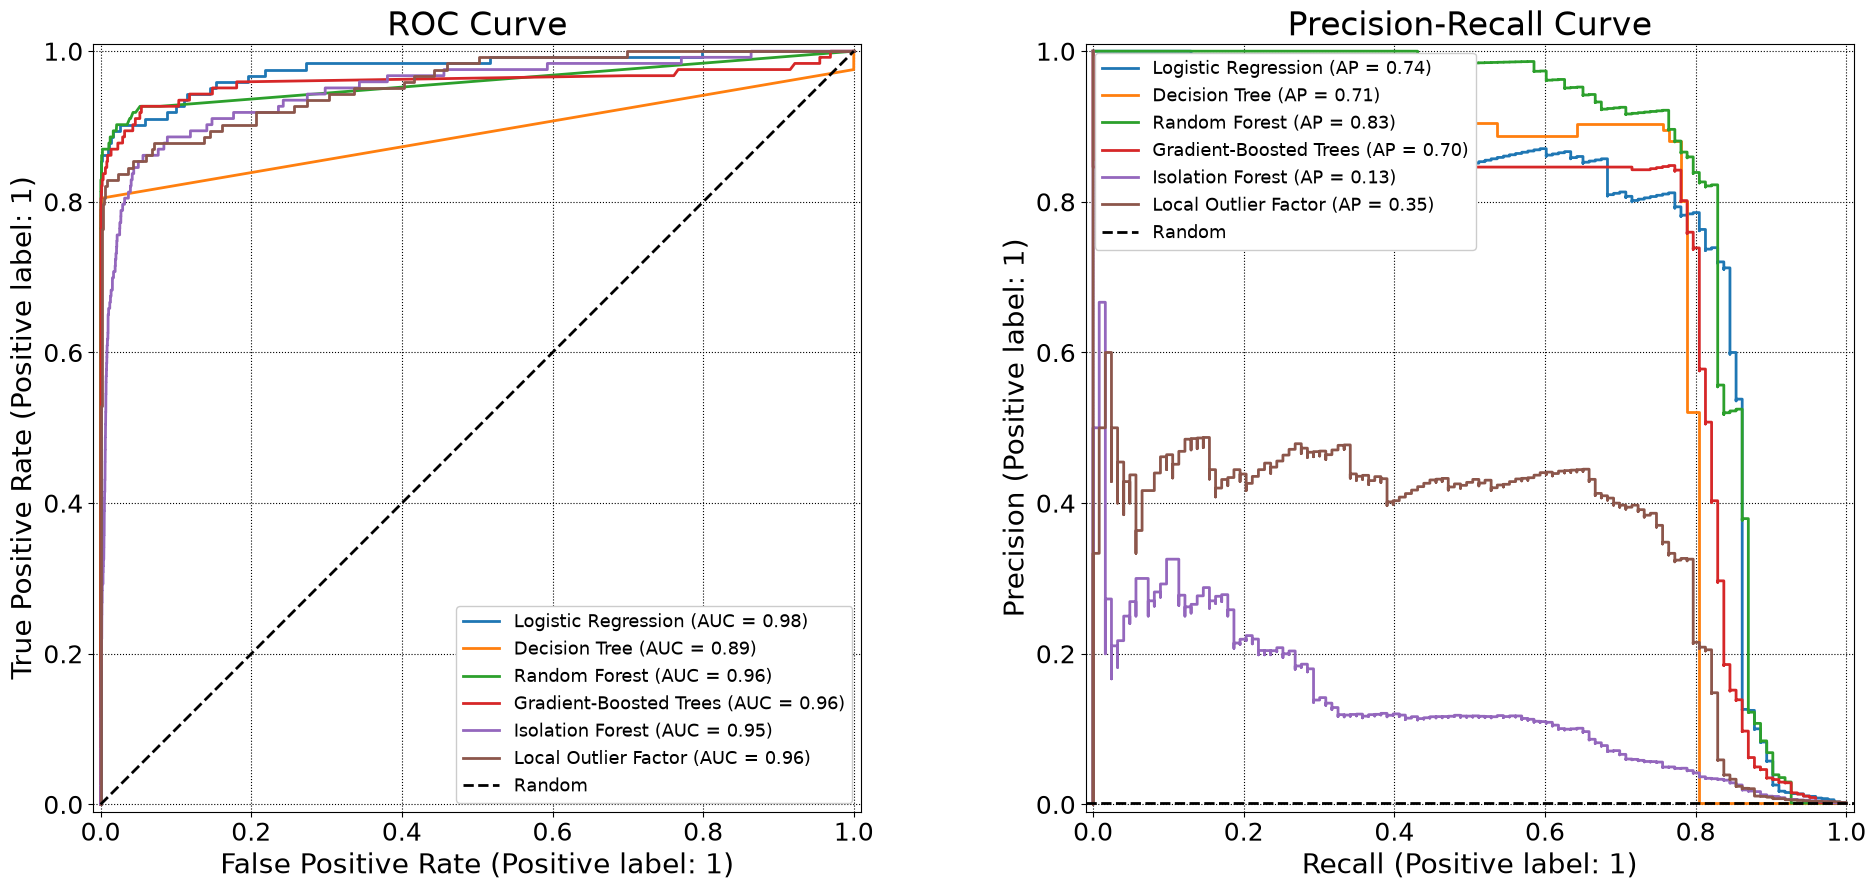

In [18]:
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (20,9), facecolor = 'white')

for name, scores in test_scores.items():
    metrics.RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=axes[0])
    metrics.PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=axes[1])

axes[0].plot([0, 1], [0, 1], 'k--', label='Random')
axes[1].axhline(y_test.mean(), color='k', linestyle='--', label='Random')

for ax, title in zip(axes, ['ROC Curve', 'Precision-Recall Curve']):
    for line in ax.get_lines():
        line.set_linewidth(2)
    ax.grid(True, axis = 'both', zorder = 0, linestyle = ':', color = 'k')
    ax.tick_params(labelsize = 18)
    ax.xaxis.label.set_size(20)
    ax.yaxis.label.set_size(20)
    ax.set_title(title, fontsize = 24)
    ax.legend(fontsize = 13, framealpha = 1)
fig.tight_layout()

Most ROC curves hug the top-left corner (ROC-AUC between 0.89 and 0.98), so ROC-AUC makes nearly every model look excellent, even Isolation Forest. The precision-recall curves tell the real story: they show how hard it is to catch most of the fraud without also flagging many legitimate transactions. When the positive class is rare, PR-AUC is usually the more informative metric.

**Key takeaways**
* Frame the decision first, and only use features available at prediction time.
* Engineered features help most when features are raw.
* Split before oversampling, tuning, or anything else that uses the labels.
* Accuracy is misleading for rare events. Use precision, recall, F1, and PR-AUC.
* Choose the final model with cross-validation on training data and confirm it on the test set.